In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn openpyxl

Note: you may need to restart the kernel to use updated packages.


# 06. The story, the actions, and the limits

## What this notebook does, in plain words

This notebook gathers the findings into one short story, adds a cohort view (when customers first arrived), and lists actions in order of money impact. It also repeats the limits, because a portfolio project that hides its limits is not trustworthy.

## What a cohort is

A cohort is a group of customers who first ordered in the same month. Watching cohorts shows whether the shop keeps finding new buyers, or whether it lives off buyers it found long ago.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
plt.rcParams['figure.dpi'] = 120
ROOT = Path('..').resolve()
CHARTS = ROOT / 'charts'
CHARTS.mkdir(exist_ok=True)
DATA = ROOT / 'data' / 'processed'
RAW = ROOT / 'data' / 'raw' / 'online_retail.csv'
print('Charts folder:', CHARTS)
print('Data folder:', DATA)


Charts folder: /home/hatch/workspace/repo-builds/datanalytics-project/charts
Data folder: /home/hatch/workspace/repo-builds/datanalytics-project/data/processed


InvoiceDate
2010-12    885
2011-01    417
2011-02    380
2011-03    452
2011-04    300
2011-05    284
2011-06    242
2011-07    188
2011-08    169
2011-09    299
2011-10    358
2011-11    323
2011-12     41
Freq: M


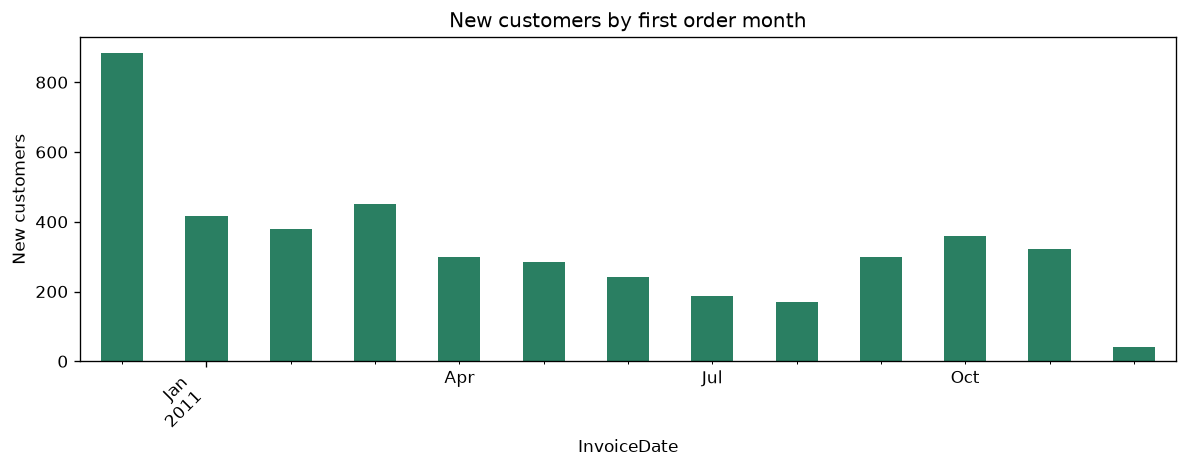

In [3]:
df = pd.read_csv(DATA / 'clean_transactions.csv', parse_dates=['InvoiceDate'])
first = df.groupby('CustomerID')['InvoiceDate'].min().dt.to_period('M')
cohort = first.value_counts().sort_index()
print(cohort.to_string())
fig, ax = plt.subplots(figsize=(10, 4))
cohort.plot(kind='bar', ax=ax, color='#2a7f62')
ax.set_title('New customers by first order month')
ax.set_ylabel('New customers')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(CHARTS / '16_new_customers_cohort.png')
plt.show()

Repeat customers, percent: 65.58
One time customers, percent: 34.42


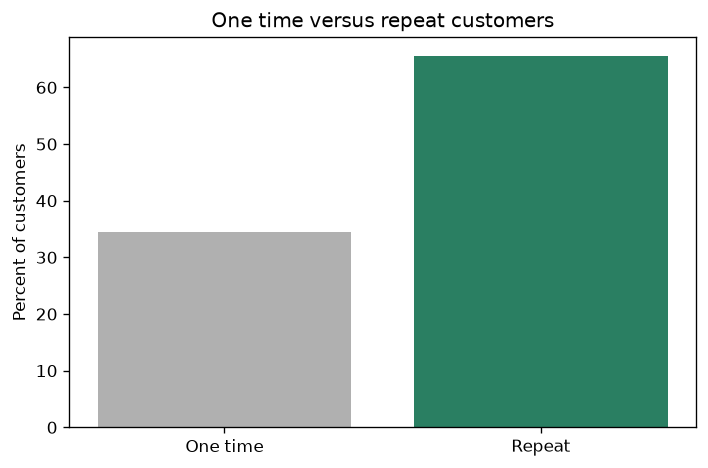

In [4]:
orders_per = df.groupby('CustomerID')['InvoiceNo'].nunique()
repeat_share = (orders_per > 1).mean() * 100
one_time_share = (orders_per == 1).mean() * 100
print('Repeat customers, percent:', round(repeat_share, 2))
print('One time customers, percent:', round(one_time_share, 2))
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['One time', 'Repeat'], [one_time_share, repeat_share], color=['#b0b0b0', '#2a7f62'])
ax.set_title('One time versus repeat customers')
ax.set_ylabel('Percent of customers')
plt.tight_layout()
plt.savefig(CHARTS / '17_repeat_vs_onetime.png')
plt.show()

## The story in five sentences

1. This is a UK gift shop, in the data, with 82.01 percent of clean revenue from the United Kingdom.
2. Sales rise into autumn, with November 2011 the best complete month at 1,161,817.38 pounds.
3. A small group carries the shop: Champions and Loyal customers are 37.5 percent of customers and 82.6 percent of revenue.
4. Most customers are not lost at once. The median customer last ordered 51 days before the end, and 33.4 percent had been quiet for over 90 days.
5. A simple forecast lags a rising trend, missing the last three complete months by 29.0 percent on average, so plan with a range, not a single number.

## Actions, in money order

1. Protect Champions first. Thank them, check stock on their favourite lines, and fix any service issue fast, because they carry 64.7 percent of revenue.
2. Contact stretched repeat buyers (gap ratio above 2) with a check in, not a blanket discount, and learn why they paused.
3. Turn recent buyers into second buyers. A second order is the cheapest growth in this data, because 34.42 percent of customers ordered only once.
4. Test one non UK market properly, instead of assuming the UK pattern travels. Netherlands and EIRE are the largest next markets in this data.
5. Staff and stock for Thursday and midday, and for the autumn peak, using the timing charts in notebook 02.

## Limits, stated plainly

- The data end on 9 December 2011, so nothing here describes today. Prices, products, and shopping habits have changed since then.
- December 2011 is partial, and 135,080 raw rows have no CustomerID, so customer counts exclude guest and manual lines.
- RFM segments are a teaching choice. Different cutoffs would move customers between groups.
- The forecast is a 3 month average. It has no seasonality model, no price model, and no promotion data, and its backtest miss is 29.0 percent.
- The gap ratio and the CLV estimate are signals and estimates, not proven churn predictions or booked revenue.
- Many customers are wholesalers, so a large order is normal for them, and a consumer reading of the same numbers would mislead.

## How to rebuild this project

Run scripts/download_data.py, then scripts/build_processed.py, then execute notebooks 01 to 06 in order. Each notebook saves its charts to charts/, and the processed tables to data/processed/. The original repo files are not part of this folder, and they are listed in BUILD_REPORT.md, so nothing from the original repo is overwritten here.